# DPA - Part 1: Network Traffic Analysis

1. What traffic patterns distinguish normal activity from attacks?
2. Which network services and traffic characteristics are associated with different attack categories?

Run the cells from top to bottom. Steps 1-3 inspect and test small samples. Steps 4-7 use all original traffic files. The source CSVs are kept unchanged.

## Optional - Download the data

Set `DOWNLOAD_DATA = True` to download the original traffic and IANA. Leave it `False` when the files are already present. Run the setup cell either way to set the folder paths.

In [1]:
DOWNLOAD_DATA = False  # Set to True if you need to download the data.

from pathlib import Path

project_folder = Path.cwd().resolve()
if project_folder.name == "notebooks":
    project_folder = project_folder.parent
elif (project_folder / "DPA-Volume-Part1-Project" / "downloaders").is_dir():
    project_folder = project_folder / "DPA-Volume-Part1-Project"
if not (project_folder / "downloaders" / "download_data.py").is_file():
    raise FileNotFoundError("Open the notebook from the project folder or notebooks/.")

data_folder = project_folder / "data"
parquet_folder = data_folder / "parquet"
print("Project folder:", project_folder)

if DOWNLOAD_DATA:
    import runpy
    downloader = runpy.run_path(str(project_folder / "downloaders" / "download_data.py"))
    downloader["download_traffic"](data_folder)
    downloader["download_iana"](data_folder)
    print("Data is ready.")
else:
    print("Download skipped.")


Project folder: /home/jovyan/work
Download skipped.


## Step 1 - Check the source files

Read the headers and the first 500 rows of each traffic file. These samples help check the format; they do not describe the full dataset. Read the whole IANA file because it is small.

In [2]:
import csv
from collections import Counter
from itertools import islice

traffic_folder = data_folder / "Dataset Network Traffic"
traffic_files = sorted(traffic_folder.glob("*.csv"))
iana_file = data_folder / "Dataset Service and Port" / "service-names-port-numbers.csv"
assert traffic_files, f"No traffic CSVs found in {traffic_folder}"
assert iana_file.is_file(), f"IANA file not found: {iana_file}"

for path in traffic_files:
    print(path.name, f"{path.stat().st_size / 1024**3:.2f} GiB")


Friday-02-03-2018_TrafficForML_CICFlowMeter.csv 0.33 GiB
Friday-16-02-2018_TrafficForML_CICFlowMeter.csv 0.31 GiB
Friday-23-02-2018_TrafficForML_CICFlowMeter.csv 0.36 GiB
Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv 3.78 GiB
Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv 0.10 GiB
Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv 0.35 GiB
Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv 0.36 GiB
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv 0.33 GiB
Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv 0.31 GiB
Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv 0.19 GiB


### 1A - Check the headers

Nine traffic files have 80 columns. The 20 February file has four extra fields. Each file must match one of these two layouts.

In [3]:
traffic_headers = {}
for path in traffic_files:
    with path.open(encoding="utf-8-sig", newline="") as source:
        header = next(csv.reader(source))
    assert len(header) == len(set(header)), f"Repeated column names: {path.name}"
    traffic_headers[path.name] = header
    print(path.name, len(header), "columns")


Friday-02-03-2018_TrafficForML_CICFlowMeter.csv 80 columns
Friday-16-02-2018_TrafficForML_CICFlowMeter.csv 80 columns
Friday-23-02-2018_TrafficForML_CICFlowMeter.csv 80 columns
Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv 84 columns
Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv 80 columns
Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv 80 columns
Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv 80 columns
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv 80 columns
Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv 80 columns
Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv 80 columns


### 1B - Read small samples

Keep the first 500 rows per file for the reading test in Step 3.

In [4]:
sample_rows = []
file_samples = {}
for path in traffic_files:
    with path.open(encoding="utf-8-sig", newline="") as source:
        rows = list(islice(csv.DictReader(source), 500))
    file_samples[path.name] = rows
    sample_rows.extend(rows)
print("Sample rows:", len(sample_rows))


Sample rows: 5000


### 1C - Look at the sample values

Print the labels, protocol codes, and a few records. These counts describe the samples only.

In [5]:
print("Sample labels:", dict(Counter(row["Label"] for row in sample_rows)))
print("Sample protocols:", dict(Counter(row["Protocol"] for row in sample_rows)))
for row in sample_rows[:3]:
    print({name: row[name] for name in ["Dst Port", "Protocol", "Timestamp", "Flow Duration", "Label"]})


Sample labels: {'Benign': 2904, 'DoS attacks-SlowHTTPTest': 403, 'Brute Force -Web': 275, 'DDoS attacks-LOIC-HTTP': 437, 'Label': 1, 'DoS attacks-GoldenEye': 456, 'FTP-BruteForce': 405, 'DDOS attack-LOIC-UDP': 119}
Sample protocols: {'6': 3200, '0': 599, '17': 1200, 'Protocol': 1}
{'Dst Port': '443', 'Protocol': '6', 'Timestamp': '02/03/2018 08:47:38', 'Flow Duration': '141385', 'Label': 'Benign'}
{'Dst Port': '49684', 'Protocol': '6', 'Timestamp': '02/03/2018 08:47:38', 'Flow Duration': '281', 'Label': 'Benign'}
{'Dst Port': '443', 'Protocol': '6', 'Timestamp': '02/03/2018 08:47:40', 'Flow Duration': '279824', 'Label': 'Benign'}


### 1D - Check IANA

Check the service name, port, and protocol fields. Some port values are ranges and must stay as text until cleaning.

In [6]:
with iana_file.open(encoding="utf-8-sig", newline="") as source:
    reader = csv.DictReader(source)
    iana_header = reader.fieldnames
    iana_records = list(reader)
print("IANA rows:", len(iana_records))
print("IANA columns:", iana_header)
assert len(iana_header) == len(set(iana_header)), "Repeated IANA column names"
for name in ["Service Name", "Port Number", "Transport Protocol"]:
    print(name, "missing:", sum(not row[name].strip() for row in iana_records))


IANA rows: 14536
IANA columns: ['Service Name', 'Port Number', 'Transport Protocol', 'Description', 'Assignee', 'Contact', 'Registration Date', 'Modification Date', 'Reference', 'Service Code', 'Unauthorized Use Reported', 'Assignment Notes']
Service Name missing: 1724
Port Number missing: 1073
Transport Protocol missing: 1467


## Step 2 - Define the schemas

Write the column names and types explicitly. Ports and protocols are integers, counts use long integers, and rates and byte totals use doubles. Dates stay as text until cleaning. Missing values are allowed here and checked in Step 4.

In [7]:
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, LongType, DoubleType

traffic_schema = StructType([
    StructField("Dst Port", IntegerType(), True),
    StructField("Protocol", IntegerType(), True),
    StructField("Timestamp", StringType(), True),
    StructField("Flow Duration", LongType(), True),
    StructField("Tot Fwd Pkts", LongType(), True),
    StructField("Tot Bwd Pkts", LongType(), True),
    StructField("TotLen Fwd Pkts", DoubleType(), True),
    StructField("TotLen Bwd Pkts", DoubleType(), True),
    StructField("Fwd Pkt Len Max", DoubleType(), True),
    StructField("Fwd Pkt Len Min", DoubleType(), True),
    StructField("Fwd Pkt Len Mean", DoubleType(), True),
    StructField("Fwd Pkt Len Std", DoubleType(), True),
    StructField("Bwd Pkt Len Max", DoubleType(), True),
    StructField("Bwd Pkt Len Min", DoubleType(), True),
    StructField("Bwd Pkt Len Mean", DoubleType(), True),
    StructField("Bwd Pkt Len Std", DoubleType(), True),
    StructField("Flow Byts/s", DoubleType(), True),
    StructField("Flow Pkts/s", DoubleType(), True),
    StructField("Flow IAT Mean", DoubleType(), True),
    StructField("Flow IAT Std", DoubleType(), True),
    StructField("Flow IAT Max", DoubleType(), True),
    StructField("Flow IAT Min", DoubleType(), True),
    StructField("Fwd IAT Tot", DoubleType(), True),
    StructField("Fwd IAT Mean", DoubleType(), True),
    StructField("Fwd IAT Std", DoubleType(), True),
    StructField("Fwd IAT Max", DoubleType(), True),
    StructField("Fwd IAT Min", DoubleType(), True),
    StructField("Bwd IAT Tot", DoubleType(), True),
    StructField("Bwd IAT Mean", DoubleType(), True),
    StructField("Bwd IAT Std", DoubleType(), True),
    StructField("Bwd IAT Max", DoubleType(), True),
    StructField("Bwd IAT Min", DoubleType(), True),
    StructField("Fwd PSH Flags", LongType(), True),
    StructField("Bwd PSH Flags", LongType(), True),
    StructField("Fwd URG Flags", LongType(), True),
    StructField("Bwd URG Flags", LongType(), True),
    StructField("Fwd Header Len", LongType(), True),
    StructField("Bwd Header Len", LongType(), True),
    StructField("Fwd Pkts/s", DoubleType(), True),
    StructField("Bwd Pkts/s", DoubleType(), True),
    StructField("Pkt Len Min", DoubleType(), True),
    StructField("Pkt Len Max", DoubleType(), True),
    StructField("Pkt Len Mean", DoubleType(), True),
    StructField("Pkt Len Std", DoubleType(), True),
    StructField("Pkt Len Var", DoubleType(), True),
    StructField("FIN Flag Cnt", LongType(), True),
    StructField("SYN Flag Cnt", LongType(), True),
    StructField("RST Flag Cnt", LongType(), True),
    StructField("PSH Flag Cnt", LongType(), True),
    StructField("ACK Flag Cnt", LongType(), True),
    StructField("URG Flag Cnt", LongType(), True),
    StructField("CWE Flag Count", LongType(), True),
    StructField("ECE Flag Cnt", LongType(), True),
    StructField("Down/Up Ratio", DoubleType(), True),
    StructField("Pkt Size Avg", DoubleType(), True),
    StructField("Fwd Seg Size Avg", DoubleType(), True),
    StructField("Bwd Seg Size Avg", DoubleType(), True),
    StructField("Fwd Byts/b Avg", DoubleType(), True),
    StructField("Fwd Pkts/b Avg", DoubleType(), True),
    StructField("Fwd Blk Rate Avg", DoubleType(), True),
    StructField("Bwd Byts/b Avg", DoubleType(), True),
    StructField("Bwd Pkts/b Avg", DoubleType(), True),
    StructField("Bwd Blk Rate Avg", DoubleType(), True),
    StructField("Subflow Fwd Pkts", LongType(), True),
    StructField("Subflow Fwd Byts", LongType(), True),
    StructField("Subflow Bwd Pkts", LongType(), True),
    StructField("Subflow Bwd Byts", LongType(), True),
    StructField("Init Fwd Win Byts", LongType(), True),
    StructField("Init Bwd Win Byts", LongType(), True),
    StructField("Fwd Act Data Pkts", LongType(), True),
    StructField("Fwd Seg Size Min", LongType(), True),
    StructField("Active Mean", DoubleType(), True),
    StructField("Active Std", DoubleType(), True),
    StructField("Active Max", DoubleType(), True),
    StructField("Active Min", DoubleType(), True),
    StructField("Idle Mean", DoubleType(), True),
    StructField("Idle Std", DoubleType(), True),
    StructField("Idle Max", DoubleType(), True),
    StructField("Idle Min", DoubleType(), True),
    StructField("Label", StringType(), True),
])

traffic_ip_schema = StructType([
    StructField("Flow ID", StringType(), True),
    StructField("Src IP", StringType(), True),
    StructField("Src Port", IntegerType(), True),
    StructField("Dst IP", StringType(), True),
] + traffic_schema.fields)

print("Original traffic schemas:", len(traffic_schema), "and", len(traffic_ip_schema), "columns")


Original traffic schemas: 80 and 84 columns


### IANA schema

Read IANA as text because ports can contain ranges and other columns contain descriptions.

In [8]:
iana_schema = StructType([
    StructField("Service Name", StringType(), True),
    StructField("Port Number", StringType(), True),
    StructField("Transport Protocol", StringType(), True),
    StructField("Description", StringType(), True),
    StructField("Assignee", StringType(), True),
    StructField("Contact", StringType(), True),
    StructField("Registration Date", StringType(), True),
    StructField("Modification Date", StringType(), True),
    StructField("Reference", StringType(), True),
    StructField("Service Code", StringType(), True),
    StructField("Unauthorized Use Reported", StringType(), True),
    StructField("Assignment Notes", StringType(), True),
])

print("IANA schema:", len(iana_schema), "columns")

IANA schema: 12 columns


### Check the schemas

Column names and order must match each file before Spark reads it.

In [9]:
traffic_schemas = {}
for file_name, header in traffic_headers.items():
    schema = traffic_ip_schema if "Flow ID" in header else traffic_schema
    assert header == schema.fieldNames(), f"Check the columns in {file_name}"
    traffic_schemas[file_name] = schema
    print(f"Header matches: {file_name} ({len(schema)} columns)")

assert iana_header == iana_schema.fieldNames(), "Check the IANA columns"
print("IANA header matches.")


Header matches: Friday-02-03-2018_TrafficForML_CICFlowMeter.csv (80 columns)
Header matches: Friday-16-02-2018_TrafficForML_CICFlowMeter.csv (80 columns)
Header matches: Friday-23-02-2018_TrafficForML_CICFlowMeter.csv (80 columns)
Header matches: Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv (84 columns)
Header matches: Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv (80 columns)
Header matches: Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv (80 columns)
Header matches: Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv (80 columns)
Header matches: Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv (80 columns)
Header matches: Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv (80 columns)
Header matches: Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv (80 columns)
IANA header matches.


## Step 3 - Test CSV to Parquet

Use the 5,000 sample rows and the whole IANA file to check reading, types, and Parquet saving before processing all traffic.

### 3A - Save the samples and start Spark

Save one sample CSV per file. Start Spark with two local worker threads.

In [10]:
sample_folder = data_folder / "samples"
sample_folder.mkdir(parents=True, exist_ok=True)
for path in traffic_files:
    with (sample_folder / path.name).open("w", encoding="utf-8", newline="") as output:
        writer = csv.DictWriter(output, fieldnames=traffic_headers[path.name])
        writer.writeheader()
        writer.writerows(file_samples[path.name])

from pyspark.sql import SparkSession
spark = (SparkSession.builder.master("local[2]")
         .appName("DPA-Volume")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.shuffle.partitions", "4").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Sample traffic records:", len(sample_rows))


Sample traffic records: 5000


### 3B - Read the CSVs

Use the explicit schemas. Keep malformed sample rows in `_corrupt_record` so the test also shows input problems. IANA uses `multiLine=True` for quoted descriptions with line breaks. `unionByName` fills the four absent IP-related fields with nulls in the other nine files.

In [11]:
sample_parts = []
for path in traffic_files:
    schema = StructType(traffic_schemas[path.name].fields + [StructField("_corrupt_record", StringType(), True)])
    part = (spark.read.schema(schema)
             .option("header", True).option("enforceSchema", False)
             .option("mode", "PERMISSIVE").option("escape", '"')
             .csv(str(sample_folder / path.name)))
    sample_parts.append(part)

sample_traffic = sample_parts[0]
for part in sample_parts[1:]:
    sample_traffic = sample_traffic.unionByName(part, allowMissingColumns=True)

iana_source = (spark.read.schema(iana_schema)
           .option("header", True).option("enforceSchema", False)
           .option("mode", "FAILFAST").option("escape", '"')
           .option("multiLine", True).csv(str(iana_file)))

sample_traffic = sample_traffic.toDF(*[name.lower().replace(" ", "_").replace("/", "_") for name in sample_traffic.columns])
iana_source = iana_source.toDF(*[name.lower().replace(" ", "_") for name in iana_source.columns])

sample_traffic.select("dst_port", "protocol", "flow_duration", "label").printSchema()
sample_traffic.select("dst_port", "protocol", "flow_duration", "label").show(5)


root
 |-- dst_port: integer (nullable = true)
 |-- protocol: integer (nullable = true)
 |-- flow_duration: long (nullable = true)
 |-- label: string (nullable = true)



+--------+--------+-------------+------+
|dst_port|protocol|flow_duration| label|
+--------+--------+-------------+------+
|     443|       6|       141385|Benign|
|   49684|       6|          281|Benign|
|     443|       6|       279824|Benign|
|     443|       6|          132|Benign|
|     443|       6|       274016|Benign|
+--------+--------+-------------+------+
only showing top 5 rows


### 3C - Save and check Parquet

Write the sample tables, read them back, and compare row counts and column types.

In [12]:
sample_tables = parquet_folder / "sample"
sample_traffic.write.mode("overwrite").parquet(str(sample_tables / "traffic"))
iana_source.write.mode("overwrite").parquet(str(sample_tables / "iana"))

traffic_parquet = spark.read.parquet(str(sample_tables / "traffic"))
iana_parquet = spark.read.parquet(str(sample_tables / "iana"))

for name, original, restored, expected in [
    ("Traffic", sample_traffic, traffic_parquet, len(sample_rows)),
    ("IANA", iana_source, iana_parquet, len(iana_records)),
]:
    actual = restored.count()
    assert actual == expected, f"{name}: row count changed"
    assert original.dtypes == restored.dtypes, f"{name}: column types changed"
    print(f"{name}: {actual} rows; types preserved.")

print("Step 3 passed. Parquet saved in:", sample_tables)
print("Malformed sample rows:", traffic_parquet.filter("_corrupt_record IS NOT NULL").count())


Traffic: 5000 rows; types preserved.


IANA: 14536 rows; types preserved.
Step 3 passed. Parquet saved in: /home/jovyan/work/data/parquet/sample


Malformed sample rows: 1


## Step 4 - Read and clean all data

Read all ten original files with their schemas and save typed Parquet. Then clean the working tables. Record the rows removed or changed at each step.

### 4A - Read all files and save raw Parquet

Keep parsing failures in `_corrupt_record` so we can count them. Check all CSV fields, and keep `source_file` to identify each day's records. The absent IP fields in nine files are expected.

In [13]:
from pyspark.sql import functions as F
from pyspark import StorageLevel

spark.conf.set("spark.sql.csv.parser.columnPruning.enabled", "false")
spark.conf.set("spark.sql.shuffle.partitions", "16")
traffic_parts = []
for path in traffic_files:
    schema = StructType(traffic_schemas[path.name].fields + [StructField("_corrupt_record", StringType(), True)])
    part = (spark.read.schema(schema)
             .option("header", True).option("enforceSchema", False)
             .option("mode", "PERMISSIVE").option("escape", '"')
             .option("columnNameOfCorruptRecord", "_corrupt_record")
             .csv(str(path)).withColumn("source_file", F.lit(path.name)))
    traffic_parts.append(part)
traffic_source = traffic_parts[0]
for part in traffic_parts[1:]:
    traffic_source = traffic_source.unionByName(part, allowMissingColumns=True)
traffic_source = traffic_source.toDF(*[column.lower().replace(" ", "_").replace("/", "_") for column in traffic_source.columns])

raw_folder = parquet_folder / "raw"
traffic_source.write.mode("overwrite").parquet(str(raw_folder / "traffic"))
iana_source.write.mode("overwrite").parquet(str(raw_folder / "iana"))
raw_traffic = spark.read.parquet(str(raw_folder / "traffic"))
raw_iana = spark.read.parquet(str(raw_folder / "iana"))
print("Original files processed:", len(traffic_files))
raw_traffic.groupBy("source_file").count().orderBy("source_file").show(truncate=False)


Original files processed: 10


+--------------------------------------------------+-------+
|source_file                                       |count  |
+--------------------------------------------------+-------+
|Friday-02-03-2018_TrafficForML_CICFlowMeter.csv   |1048575|
|Friday-16-02-2018_TrafficForML_CICFlowMeter.csv   |1048575|
|Friday-23-02-2018_TrafficForML_CICFlowMeter.csv   |1048575|
|Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv |7948748|
|Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv |331125 |
|Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv |1048575|
|Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv |1048575|
|Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv|1048575|
|Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv|1048575|
|Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv|613104 |
+--------------------------------------------------+-------+



### Keep the cleaning counts

Record input, removed, modified, and remaining rows with a reason. Each step starts from the previous result, so removed rows are counted once.

In [14]:
audit_rows = []

def record_step(dataset, step, before, after, reason, modified=0):
    audit_rows.append((dataset, step, before, before - after, modified, after, reason))
    print(f"{dataset} | {step}: {before:,} -> {after:,}; removed {before - after:,}; modified {modified:,}")
    return after

traffic = raw_traffic
iana = raw_iana
traffic_count = traffic.count()
iana_count = iana.count()
print(f"Input rows: traffic={traffic_count:,}, IANA={iana_count:,}")


Input rows: traffic=16,233,002, IANA=14,536


### 4B - Remove badly formatted records

Rows with invalid numbers or the wrong field count do not match the schema. Remove them from the working data; raw Parquet retains the original text.

In [15]:
traffic = traffic.filter(F.col("_corrupt_record").isNull()).drop("_corrupt_record")
traffic_count = record_step("traffic", "Malformed records", traffic_count, traffic.count(),
                            "Remove CSV structure or numeric parsing failures; raw evidence retained")


traffic | Malformed records: 16,233,002 -> 16,232,943; removed 59; modified 0


### 4C - Remove duplicate records

Compare all typed source columns before dropping any columns. Keep one copy per traffic file and one copy of each IANA row. Matching CSV rows are not proof of the same real network event.

In [16]:
traffic = traffic.dropDuplicates().persist(StorageLevel.DISK_ONLY)
traffic_count = record_step("traffic", "Duplicate records", traffic_count, traffic.count(),
                            "Keep one matching typed source record per file, comparing all source columns")
iana = iana.dropDuplicates()
iana_count = record_step("iana", "Duplicate records", iana_count, iana.count(),
                         "Keep one copy of each complete registry record")


traffic | Duplicate records: 16,232,943 -> 15,822,236; removed 410,707; modified 0


iana | Duplicate records: 14,536 -> 14,536; removed 0; modified 0


### 4D - Keep the columns needed for analysis

Keep traffic labels, times, measurements, port, protocol, and filename. For IANA, keep service name, port, and protocol. Raw Parquet still has all columns. Persist the reduced traffic table on disk to avoid repeating the duplicate check.

In [17]:
traffic_columns = ["dst_port", "protocol", "timestamp", "flow_duration", "tot_fwd_pkts", "tot_bwd_pkts",
                    "totlen_fwd_pkts", "totlen_bwd_pkts", "flow_byts_s", "flow_pkts_s", "label"]
unique_traffic = traffic
selected_traffic = unique_traffic.select(*traffic_columns, "source_file").persist(StorageLevel.DISK_ONLY)
traffic = selected_traffic
traffic_count = record_step("traffic", "Select analysis columns", traffic_count, traffic.count(),
                            "Keep 11 research fields and source_file; raw table retains all columns")
unique_traffic.unpersist()
iana = iana.select("service_name", "port_number", "transport_protocol")
iana_count = record_step("iana", "Select lookup columns", iana_count, iana_count,
                         "Keep service name, port number, and transport protocol")


traffic | Select analysis columns: 15,822,236 -> 15,822,236; removed 0; modified 0
iana | Select lookup columns: 14,536 -> 14,536; removed 0; modified 0


### 4E - Fix text formats

Trim spaces, turn empty text into null, and lowercase IANA protocol names so the join keys match. Keep the supplied attack-label spelling.

In [18]:
changed_traffic_rows = traffic.filter(
    (F.col("label") != F.trim("label")) | (F.trim("label") == "") |
    (F.col("timestamp") != F.trim("timestamp")) | (F.trim("timestamp") == "")).count()
for column in ["label", "timestamp"]:
    traffic = traffic.withColumn(column, F.when(F.trim(column) != "", F.trim(column)))
traffic_count = record_step("traffic", "Normalize text", traffic_count, traffic_count,
                            "Trim labels/timestamps and turn blank text into null", changed_traffic_rows)

changed_iana_rows = iana.filter(
    (F.col("service_name") != F.trim("service_name")) | (F.trim("service_name") == "") |
    (F.col("port_number") != F.trim("port_number")) | (F.trim("port_number") == "") |
    (F.col("transport_protocol") != F.lower(F.trim("transport_protocol"))) |
    (F.trim("transport_protocol") == "")).count()
for column in iana.columns:
    iana = iana.withColumn(column, F.when(F.trim(column) != "", F.trim(column)))
iana = iana.withColumn("transport_protocol", F.lower("transport_protocol"))
iana_count = record_step("iana", "Normalize text", iana_count, iana_count,
                         "Trim lookup fields, lowercase protocols, and turn blank text into null", changed_iana_rows)


traffic | Normalize text: 15,822,236 -> 15,822,236; removed 0; modified 0


iana | Normalize text: 14,536 -> 14,536; removed 0; modified 0


### 4F - Check and remove missing values

Count missing values first. Drop null or NaN in the required analysis and lookup fields. Filling in labels, dates, or rates would add guesses. The absent IP fields are not required and are excluded from this check.

In [19]:
numeric_columns = [column for column in traffic_columns if column not in ["label", "timestamp"]]
missing_checks = []
for column in traffic_columns:
    missing = F.col(column).isNull()
    if column in numeric_columns:
        missing = missing | F.isnan(column)
    missing_checks.append(F.sum(F.when(missing, 1).otherwise(0)).alias(column))
missing_counts = traffic.select(*missing_checks).first().asDict()
print("Traffic missing values before this rule:", {column: n for column, n in missing_counts.items() if n})
print("IANA missing values before this rule:", iana.select(*[
    F.sum(F.when(F.col(column).isNull(), 1).otherwise(0)).alias(column) for column in iana.columns]).first().asDict())
traffic = traffic.na.drop(subset=traffic_columns)
traffic_count = record_step("traffic", "Missing required values", traffic_count, traffic.count(),
                            "Drop null/NaN in required research fields; do not impute traffic or labels")
iana = iana.na.drop(subset=["service_name", "port_number", "transport_protocol"])
iana_count = record_step("iana", "Missing lookup values", iana_count, iana.count(),
                         "A named-service lookup requires service, port, and transport protocol")


Traffic missing values before this rule: {'flow_byts_s': 58343}


IANA missing values before this rule: {'service_name': 1724, 'port_number': 1073, 'transport_protocol': 1467}


traffic | Missing required values: 15,822,236 -> 15,763,893; removed 58,343; modified 0


iana | Missing lookup values: 14,536 -> 11,723; removed 2,813; modified 0


### 4G - Remove infinite values

Infinite measurements cannot be used in the comparisons. Missing values were removed first, so a row with both problems is counted once.

In [20]:
valid_numbers = F.lit(True)
for column in numeric_columns:
    valid_numbers = valid_numbers & (F.abs(F.col(column).cast("double")) != F.lit(float("inf")))
traffic = traffic.filter(valid_numbers)
traffic_count = record_step("traffic", "Infinite measurements", traffic_count, traffic.count(),
                            "Retained numeric measurements must be finite")


traffic | Infinite measurements: 15,763,893 -> 15,727,888; removed 36,005; modified 0


### 4H - Remove impossible values

Reject negative measurements, ports outside 0-65535, protocols outside 0-255, and positive bytes without packets in that direction. Keep large finite values because they can represent attacks. Zero durations and ports are retained.

In [21]:
valid_values = F.col("dst_port").between(0, 65535) & F.col("protocol").between(0, 255)
for column in ["flow_duration", "tot_fwd_pkts", "tot_bwd_pkts", "totlen_fwd_pkts", "totlen_bwd_pkts",
          "flow_byts_s", "flow_pkts_s"]:
    valid_values = valid_values & (F.col(column) >= 0)
valid_values = valid_values & ((F.col("tot_fwd_pkts") > 0) | (F.col("totlen_fwd_pkts") == 0))
valid_values = valid_values & ((F.col("tot_bwd_pkts") > 0) | (F.col("totlen_bwd_pkts") == 0))
traffic = traffic.filter(valid_values)
traffic_count = record_step("traffic", "Impossible measurements or codes", traffic_count, traffic.count(),
                            "Reject negative measurements, invalid port/protocol ranges, and bytes without packets")


traffic | Impossible measurements or codes: 15,727,888 -> 15,727,874; removed 14; modified 0


### 4I - Convert and check dates

Parse day/month/year, including fractional seconds. Remove invalid timestamps and dates outside 14 February to 2 March 2018. Keep the source clock times because no timezone is supplied. Count valid text-to-timestamp conversions as modifications.

In [22]:
traffic = traffic.withColumn("timestamp", F.coalesce(
    F.try_to_timestamp("timestamp", F.lit("dd/MM/yyyy HH:mm:ss")),
    F.try_to_timestamp("timestamp", F.lit("dd/MM/yyyy HH:mm:ss.SSSSSS"))))
traffic = traffic.filter(
    F.col("timestamp").isNotNull() &
    (F.col("timestamp") >= F.lit("2018-02-14").cast("timestamp")) &
    (F.col("timestamp") < F.lit("2018-03-03").cast("timestamp")))
date_count = traffic.count()
traffic_count = record_step("traffic", "Parse and validate timestamps", traffic_count, date_count,
                            "Convert valid timestamps; reject invalid dates outside the collection period", date_count)


traffic | Parse and validate timestamps: 15,727,874 -> 15,727,874; removed 0; modified 15,727,874


### 4J - Prepare IANA ports

Keep individual TCP/UDP ports and convert them to integers. Exclude ranges and other protocols from this lookup. These excluded entries are not necessarily dirty data.

In [23]:
iana = iana.filter(
    F.col("port_number").rlike(r"^[0-9]{1,5}$") & F.col("transport_protocol").isin("tcp", "udp"))
iana = iana.withColumn("port_number", F.col("port_number").cast("int"))
iana = iana.filter(F.col("port_number").between(0, 65535))
port_count = iana.count()
iana_count = record_step("iana", "Individual TCP/UDP ports", iana_count, port_count,
                         "Lookup scope: individual TCP/UDP registrations; convert retained ports to integers", port_count)


iana | Individual TCP/UDP ports: 11,723 -> 11,623; removed 100; modified 11,623


### 4K - Combine service aliases

Several names can share one port and protocol. Combine the names into one lookup row so the join cannot multiply traffic rows.

In [24]:
services_by_port = iana.groupBy("port_number", "transport_protocol").agg(
    F.sort_array(F.collect_set("service_name")).alias("service_names"))
changed_services = services_by_port.filter(F.size("service_names") > 1).count()
iana = services_by_port.select("port_number", "transport_protocol",
                                 F.concat_ws(", ", "service_names").alias("service_name"))
iana_count = record_step("iana", "Combine service aliases", iana_count, iana.count(),
                         "Aggregate all distinct service names into one row per port/protocol; prevent join multiplication", changed_services)


iana | Combine service aliases: 11,623 -> 11,391; removed 232; modified 226


### 4L - Save cleaned data and cleaning counts

Write cleaned Parquet, check its counts and types, and save the cleaning log as CSV.

In [25]:
clean_folder = parquet_folder / "cleaned"
traffic.write.mode("overwrite").parquet(str(clean_folder / "traffic"))
iana.write.mode("overwrite").parquet(str(clean_folder / "iana"))
clean_traffic = spark.read.parquet(str(clean_folder / "traffic"))
clean_iana = spark.read.parquet(str(clean_folder / "iana"))
assert clean_traffic.count() == traffic_count
assert clean_iana.count() == iana_count
assert clean_traffic.dtypes == traffic.dtypes
assert clean_iana.dtypes == iana.dtypes
selected_traffic.unpersist()

audit_columns = ["dataset", "step", "input_rows", "removed_rows", "modified_rows", "output_rows", "reason"]
cleaning_audit = spark.createDataFrame(audit_rows, audit_columns)
cleaning_audit.show(truncate=False)
audit_folder = project_folder / "reports" / "cleaning" / "original"
audit_folder.mkdir(parents=True, exist_ok=True)
with (audit_folder / "cleaning_audit.csv").open("w", encoding="utf-8", newline="") as output:
    writer = csv.writer(output)
    writer.writerow(audit_columns)
    writer.writerows(audit_rows)
print("Cleaned Parquet:", clean_folder)
print("Cleaning audit:", audit_folder / "cleaning_audit.csv")


+-------+--------------------------------+----------+------------+-------------+-----------+------------------------------------------------------------------------------------------------+
|dataset|step                            |input_rows|removed_rows|modified_rows|output_rows|reason                                                                                          |
+-------+--------------------------------+----------+------------+-------------+-----------+------------------------------------------------------------------------------------------------+
|traffic|Malformed records               |16233002  |59          |0            |16232943   |Remove CSV structure or numeric parsing failures; raw evidence retained                         |
|traffic|Duplicate records               |16232943  |410707      |0            |15822236   |Keep one matching typed source record per file, comparing all source columns                    |
|iana   |Duplicate records               |14536   

## Step 5 - Add IANA service names

Join the cleaned tables using destination port and protocol. IANA names are registered port associations; they do not verify the application or its 2018 assignment.

### 5A - Prepare the join keys

Convert protocol 6 to `tcp` and 17 to `udp`. Rename IANA's port column to match traffic. Check that each lookup key occurs once.

In [26]:
from pyspark.sql import functions as F

clean_folder = parquet_folder / "cleaned"
traffic = spark.read.parquet(str(clean_folder / "traffic"))
iana = spark.read.parquet(str(clean_folder / "iana"))

traffic = traffic.withColumn(
    "transport_protocol",
    F.when(F.col("protocol") == 6, "tcp").when(F.col("protocol") == 17, "udp"))
iana = iana.withColumnRenamed("port_number", "dst_port")
assert iana.groupBy("dst_port", "transport_protocol").count().filter(
    F.col("count") > 1).count() == 0, "IANA has repeated join keys. Check Step 4."

rows_before = traffic.count()
print(f"Traffic rows before the join: {rows_before:,}")


Traffic rows before the join: 15,727,874


### 5B - Join the tables

A left join keeps unmatched traffic. Broadcast the small IANA table to avoid shuffling the traffic. An unmatched port does not by itself indicate an attack.

In [27]:
traffic_with_services = traffic.join(
    F.broadcast(iana), ["dst_port", "transport_protocol"], "left")


### 5C - Save and check the join

Check that the row count and types are unchanged. Print matched and unmatched counts.

In [28]:
enriched_folder = parquet_folder / "enriched" / "traffic"
traffic_with_services.write.mode("overwrite").parquet(str(enriched_folder))
final_traffic = spark.read.parquet(str(enriched_folder))
assert final_traffic.dtypes == traffic_with_services.dtypes, "Column types changed after saving."

service_counts = final_traffic.groupBy(
    F.col("service_name").isNotNull().alias("iana_match")).count().collect()
rows_after = sum(row["count"] for row in service_counts)
matched_rows = sum(row["count"] for row in service_counts if row["iana_match"])
assert rows_after == rows_before, "The join changed the traffic row count."
print(f"Traffic rows after the join: {rows_after:,}")
print(f"Matched service: {matched_rows:,}")
print(f"No service match: {rows_after - matched_rows:,}")

final_traffic.select("dst_port", "protocol", "transport_protocol", "service_name", "label").show(10, truncate=False)
print("Enriched Parquet:", enriched_folder)


Traffic rows after the join: 15,727,874
Matched service: 12,805,625
No service match: 2,922,249
+--------+--------+------------------+-------------------+------+
|dst_port|protocol|transport_protocol|service_name       |label |
+--------+--------+------------------+-------------------+------+
|80      |6       |tcp               |http, www, www-http|Benign|
|443     |6       |tcp               |https              |Benign|
|443     |6       |tcp               |https              |Benign|
|50574   |6       |tcp               |NULL               |Benign|
|50623   |6       |tcp               |NULL               |Benign|
|443     |6       |tcp               |https              |Benign|
|443     |6       |tcp               |https              |Benign|
|443     |6       |tcp               |https              |Benign|
|443     |6       |tcp               |https              |Benign|
|53      |17      |udp               |domain             |Benign|
+--------+--------+------------------+--------

## Step 6 - Analyse the traffic

Use all cleaned traffic to compare normal and attack labels and their services. `Benign` means normal traffic. Counts refer to CSV traffic records, not unique users or individual packets.

### 6A - Prepare the measurements

Add forward and backward counts to get total packets and recorded bytes. Keep timestamps and filenames for the records-per-minute calculation.

In [2]:
traffic_data = spark.read.parquet(str(parquet_folder / "enriched" / "traffic")).select(
    "label", "dst_port", "protocol", "service_name", "timestamp", "source_file",
    F.when(F.col("label") == "Benign", "Normal").otherwise("Attack").alias("traffic_type"),
    (F.col("tot_fwd_pkts") + F.col("tot_bwd_pkts")).alias("packets"),
    (F.col("totlen_fwd_pkts") + F.col("totlen_bwd_pkts")).alias("bytes"),
    "flow_pkts_s")


### 6B - Count and summarize each label

For Graph 1A, divide total recorded bytes by total packets in each group. For Graph 1B, find the middle packet rate (the approximate median). Count all labels, including those not displayed in the graphs.

In [3]:
summary_columns = [
    F.count("*").alias("flows"),
    F.round(F.try_divide(F.sum("bytes"), F.sum("packets")), 2).alias("bytes_per_packet"),
    F.round(F.percentile_approx("flow_pkts_s", 0.5), 2).alias("median_packets_s"),
]

label_summary = (traffic_data.groupBy("label")
    .agg(*summary_columns,
         F.sum(F.when(F.col("service_name").isNotNull(), 1).otherwise(0)).alias("matched_flows"))
    .orderBy(F.desc("flows"), "label").cache())
total_flows = label_summary.agg(F.sum("flows")).first()[0]
assert total_flows is not None and total_flows > 0, "The enriched traffic table is empty."
print(f"Flows used in the analysis: {total_flows:,}")

label_counts = label_summary.select("label", "flows").withColumn(
    "percent_of_all", F.round(F.col("flows") / total_flows * 100, 4))
label_counts.show(30, truncate=False)


Flows used in the analysis: 15,727,874


+------------------------+--------+--------------+
|label                   |flows   |percent_of_all|
+------------------------+--------+--------------+
|Benign                  |13374907|85.0395       |
|DDOS attack-HOIC        |668461  |4.2502        |
|DDoS attacks-LOIC-HTTP  |576191  |3.6635        |
|DoS attacks-Hulk        |434873  |2.765         |
|Bot                     |282310  |1.795         |
|Infilteration           |160604  |1.0211        |
|SSH-Bruteforce          |117322  |0.7459        |
|DoS attacks-GoldenEye   |41455   |0.2636        |
|FTP-BruteForce          |39346   |0.2502        |
|DoS attacks-SlowHTTPTest|19462   |0.1237        |
|DoS attacks-Slowloris   |10285   |0.0654        |
|DDOS attack-LOIC-UDP    |1730    |0.011         |
|Brute Force -Web        |611     |0.0039        |
|Brute Force -XSS        |230     |0.0015        |
|SQL Injection           |87      |6.0E-4        |
+------------------------+--------+--------------+



### 6C - Compare normal and attack traffic

Calculate the combined attack summary from its records. Combining per-label medians would give the wrong median. Also show the results for every source label.

In [4]:
normal_stats = (label_summary.filter(F.col("label") == "Benign")
    .drop("label", "matched_flows").withColumn("traffic_type", F.lit("Normal")))
attack_stats = (traffic_data.filter(F.col("label") != "Benign")
    .groupBy("traffic_type").agg(*summary_columns))
normal_attack = attack_stats.unionByName(normal_stats).orderBy("traffic_type").cache()
normal_attack.show(truncate=False)

label_patterns = label_summary.drop("matched_flows")
label_patterns.show(30, truncate=False)


+------------+--------+----------------+----------------+
|traffic_type|flows   |bytes_per_packet|median_packets_s|
+------------+--------+----------------+----------------+
|Attack      |2352967 |35.53           |166.82          |
|Normal      |13374907|459.02          |103.73          |
+------------+--------+----------------+----------------+



+------------------------+--------+----------------+----------------+
|label                   |flows   |bytes_per_packet|median_packets_s|
+------------------------+--------+----------------+----------------+
|Benign                  |13374907|459.02          |103.73          |
|DDOS attack-HOIC        |668461  |93.75           |474.95          |
|DDoS attacks-LOIC-HTTP  |576191  |34.2            |3.83            |
|DoS attacks-Hulk        |434873  |30.69           |145.55          |
|Bot                     |282310  |49.68           |776.74          |
|Infilteration           |160604  |264.32          |1715.27         |
|SSH-Bruteforce          |117322  |103.95          |120.98          |
|DoS attacks-GoldenEye   |41455   |150.51          |1.04            |
|FTP-BruteForce          |39346   |0.0             |400000.0        |
|DoS attacks-SlowHTTPTest|19462   |0.0             |333333.33       |
|DoS attacks-Slowloris   |10285   |116.46          |0.17            |
|DDOS attack-LOIC-UD

### 6D - Check IANA coverage

Show the share of each label with a service match before interpreting its services.

In [5]:
service_coverage = (label_summary.select("label", "flows", "matched_flows")
    .withColumn("matched_percent", F.round(F.col("matched_flows") / F.col("flows") * 100, 2)))
service_coverage.show(30, truncate=False)


+------------------------+--------+-------------+---------------+
|label                   |flows   |matched_flows|matched_percent|
+------------------------+--------+-------------+---------------+
|Benign                  |13374907|10488198     |78.42          |
|DDOS attack-HOIC        |668461  |668461       |100.0          |
|DDoS attacks-LOIC-HTTP  |576191  |576191       |100.0          |
|DoS attacks-Hulk        |434873  |434873       |100.0          |
|Bot                     |282310  |277753       |98.39          |
|Infilteration           |160604  |129643       |80.72          |
|SSH-Bruteforce          |117322  |117322       |100.0          |
|DoS attacks-GoldenEye   |41455   |41455        |100.0          |
|FTP-BruteForce          |39346   |39346        |100.0          |
|DoS attacks-SlowHTTPTest|19462   |19462        |100.0          |
|DoS attacks-Slowloris   |10285   |10285        |100.0          |
|DDOS attack-LOIC-UDP    |1730    |1730         |100.0          |
|Brute For

### 6E - Find the top services

Count destination port/protocol combinations and rank the top five within each label. Percentages use every record in that label, including unmatched records.

In [6]:
from pyspark.sql.window import Window

service_counts = traffic_data.groupBy("label", "dst_port", "protocol", "service_name").agg(
    F.count("*").alias("flows"))
port_order = Window.partitionBy("label").orderBy(F.desc("flows"), "dst_port", "protocol")
top_ports = service_counts.withColumn("rank", F.row_number().over(port_order)).filter(F.col("rank") <= 5)

label_totals = label_counts.select("label", F.col("flows").alias("label_flows"))
top_services = (top_ports.join(F.broadcast(label_totals), "label", "left")
    .withColumn("percent_of_label", F.round(F.col("flows") / F.col("label_flows") * 100, 2))
    .withColumn("service_name", F.coalesce("service_name", F.lit("No IANA match")))
    .select("label", "rank", "dst_port", "protocol", "service_name", "flows", "percent_of_label")
    .orderBy("label", "rank").cache())
top_services.show(100, truncate=False)


+------------------------+----+--------+--------+-------------------+-------+----------------+
|label                   |rank|dst_port|protocol|service_name       |flows  |percent_of_label|
+------------------------+----+--------+--------+-------------------+-------+----------------+
|Benign                  |1   |53      |17      |domain             |4020801|30.06           |
|Benign                  |2   |443     |6       |https              |1995818|14.92           |
|Benign                  |3   |3389    |6       |ms-wbt-server      |1819697|13.61           |
|Benign                  |4   |80      |6       |http, www, www-http|1678562|12.55           |
|Benign                  |5   |445     |6       |microsoft-ds       |706291 |5.28            |
|Bot                     |1   |8080    |6       |http-alt           |277753 |98.39           |
|Bot                     |2   |0       |0       |No IANA match      |258    |0.09            |
|Bot                     |3   |50891   |6       |N

### 6F - Count records per active minute

Group record starts by minute, label, and service. Then divide records by active minutes. An active minute has at least one record for that group. Each group uses its own active minutes, not matched simultaneous windows.

The five named destinations and `Other` cover all records once. Port and protocol are checked together.

In [7]:
service = (F.when((F.col("dst_port") == 21) & (F.col("protocol") == 6), "FTP (21/TCP)")
    .when((F.col("dst_port") == 22) & (F.col("protocol") == 6), "SSH (22/TCP)")
    .when((F.col("dst_port") == 80) & (F.col("protocol") == 6), "HTTP (80/TCP)")
    .when((F.col("dst_port") == 8080) & (F.col("protocol") == 6), "HTTP-alt (8080/TCP)")
    .when((F.col("dst_port") == 53) & (F.col("protocol") == 17), "DNS (53/UDP)")
    .otherwise("Other"))

minute_counts = (traffic_data.withColumn("service", service)
    .withColumn("minute", F.date_trunc("minute", "timestamp"))
    .groupBy("label", "service", "source_file", "minute").count())

service_patterns = (minute_counts.groupBy("label", "service")
    .agg(F.sum("count").alias("flows"), F.count("*").alias("active_minutes"),
         F.round(F.avg("count"), 2).alias("avg_records_min"))
    .join(F.broadcast(label_totals), "label", "left")
    .withColumn("percent_of_label", F.round(F.col("flows") / F.col("label_flows") * 100, 2))
    .orderBy("label", "service"))
service_patterns.show(100, truncate=False)


+------------------------+-------------------+-------+--------------+---------------+-----------+----------------+
|label                   |service            |flows  |active_minutes|avg_records_min|label_flows|percent_of_label|
+------------------------+-------------------+-------+--------------+---------------+-----------+----------------+
|Benign                  |DNS (53/UDP)       |4020801|4589          |876.18         |13374907   |30.06           |
|Benign                  |FTP (21/TCP)       |522    |396           |1.32           |13374907   |0.0             |
|Benign                  |HTTP (80/TCP)      |1678562|4385          |382.8          |13374907   |12.55           |
|Benign                  |HTTP-alt (8080/TCP)|573    |337           |1.7            |13374907   |0.0             |
|Benign                  |Other              |7665327|4924          |1556.73        |13374907   |57.31           |
|Benign                  |SSH (22/TCP)       |9122   |2336          |3.9        

### 6G - Save the summaries

Save the six small result tables as CSVs for the charts. Spark performs the calculations; Python collects only the summary rows. Release the cached summaries afterwards. Stop Spark after saving; the plots below read the CSV files.

In [8]:
import csv

results_folder = project_folder / "reports" / "analysis"
results_folder.mkdir(parents=True, exist_ok=True)
results = {"label_counts": label_counts, "normal_attack": normal_attack,
           "label_patterns": label_patterns, "service_coverage": service_coverage,
           "top_services": top_services, "service_patterns": service_patterns}
for name, table in results.items():
    with (results_folder / f"{name}.csv").open("w", encoding="utf-8", newline="") as output:
        writer = csv.writer(output)
        writer.writerow(table.columns)
        writer.writerows(tuple(row) for row in table.collect())
for table in [label_summary, normal_attack, top_services]:
    table.unpersist()
print("Analysis results:", results_folder)

spark.stop()


Analysis results: /home/jovyan/work/reports/analysis


## Step 7 - Plot the results

Read the full-data summaries from Step 6. The graphs show selected categories; the tables include all 15 labels. The sample rows were only used in Step 3.

A **traffic record (flow)** groups related packets in one CSV row. A **median** is the middle value after sorting; Spark estimates it here. These comparisons describe labelled groups, not a tested attack detector.

### Question 1 - What traffic patterns distinguish normal activity from attacks?

Compare normal traffic with HOIC, Bot, Infilteration, and LOIC-UDP using recorded bytes per packet and median packet rates. All cleaned records within each displayed category are included.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

label_results = pd.read_csv(project_folder / "reports" / "analysis" / "label_patterns.csv")
chart_data = label_results.set_index("label").loc[
    ["Benign", "DDOS attack-HOIC", "Bot", "Infilteration", "DDOS attack-LOIC-UDP"]]
traffic_labels = ["Normal", "HOIC", "Bot", "Infilteration", "LOIC-UDP"]
colors = ["#4472C4"] + ["#E69F00"] * 4

charts_folder = project_folder / "reports" / "charts"
charts_folder.mkdir(parents=True, exist_ok=True)


#### Graph 1A - Recorded bytes per packet

Divide the group's total recorded bytes by its total packets. Some source records have zero recorded bytes despite nonzero packet counts, so this is not verified payload size.

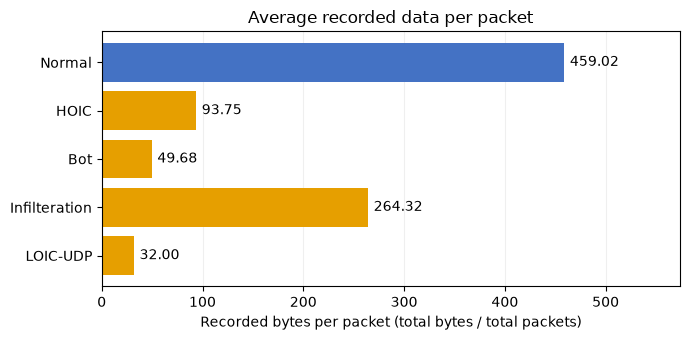

In [10]:
size = chart_data["bytes_per_packet"]
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(traffic_labels, size, color=colors)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_title("Average recorded data per packet")
ax.set_xlabel("Recorded bytes per packet (total bytes / total packets)")
ax.set_xlim(0, size.max() * 1.25)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(charts_folder / "bytes_per_packet.png", dpi=160, bbox_inches="tight")
plt.show()


#### Graph 1B - Packet rate

Show the median of the supplied packets-per-second values. This is the rate within a traffic record, not the total rate of the network.

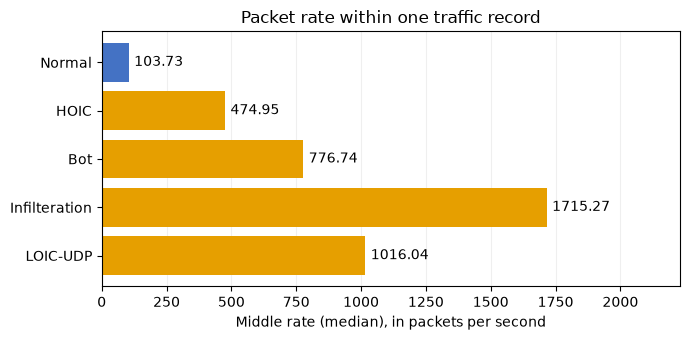

In [11]:
rate = chart_data["median_packets_s"]
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(traffic_labels, rate, color=colors)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_title("Packet rate within one traffic record")
ax.set_xlabel("Middle rate (median), in packets per second")
ax.set_xlim(0, rate.max() * 1.3)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(charts_folder / "packet_rate.png", dpi=160, bbox_inches="tight")
plt.show()


### Question 2 - Which network services and traffic characteristics are associated with different attack categories?

Graph 2A compares registered service ports. Graph 2B compares normal and attack activity on the same port and protocol. FTP is file transfer, SSH is remote access, HTTP is web traffic, and DNS is name lookup. IANA registrations do not verify actual application use.

Read the service summary. Percentages include all records in the label; `Other` includes destinations outside the five named groups.

In [12]:
service_results = pd.read_csv(project_folder / "reports" / "analysis" / "service_patterns.csv")
service_order = ["FTP (21/TCP)", "SSH (22/TCP)", "HTTP (80/TCP)",
                 "HTTP-alt (8080/TCP)", "DNS (53/UDP)", "Other"]
row_order = ["Benign", "FTP-BruteForce", "SSH-Bruteforce", "Bot",
              "DDOS attack-HOIC", "Infilteration"]
service_shares = service_results.pivot(index="label", columns="service", values="percent_of_label")
service_shares = service_shares.reindex(index=row_order, columns=service_order).fillna(0)
charts_folder = project_folder / "reports" / "charts"
charts_folder.mkdir(parents=True, exist_ok=True)


#### Graph 2A - Services by traffic category

Read each row across: darker cells mean a larger percentage of that category. Each row totals 100% before rounding. A displayed 0.0 may be a small nonzero share.

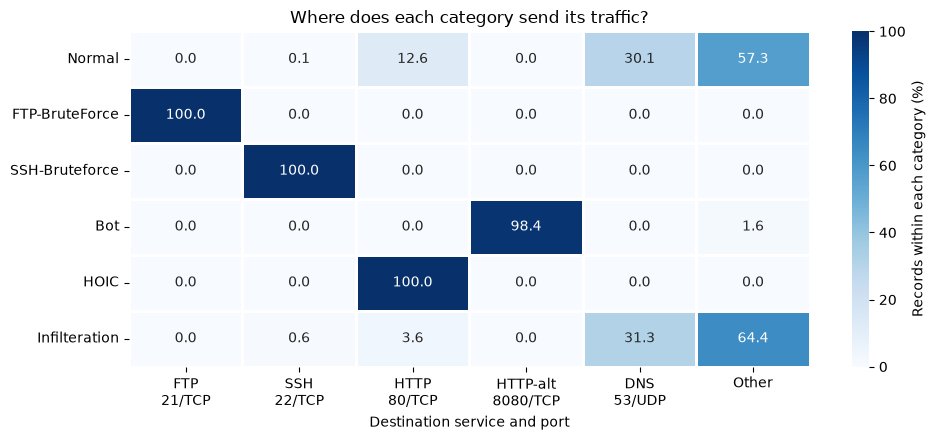

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(service_shares, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            linewidths=1, cbar_kws={"label": "Records within each category (%)"}, ax=ax)
ax.set_yticklabels(["Normal", "FTP-BruteForce", "SSH-Bruteforce", "Bot", "HOIC", "Infilteration"], rotation=0)
ax.set_xticklabels(["FTP\n21/TCP", "SSH\n22/TCP", "HTTP\n80/TCP", "HTTP-alt\n8080/TCP", "DNS\n53/UDP", "Other"], rotation=0)
ax.set_title("Where does each category send its traffic?")
ax.set_xlabel("Destination service and port")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(charts_folder / "attack_services.png", dpi=160, bbox_inches="tight")
plt.show()


#### Graph 2B - Normal and attack records per active minute

Blue is normal traffic and orange is the named attack. Bar labels show records per active minute; titles show attack rate divided by normal rate.

Each panel has its own vertical scale. Compare the two bars inside a panel and use the printed values across services. Groups use their own active minutes. These records are not counts of users or login attempts.

In [14]:
attack_services = [("FTP-BruteForce", "FTP (21/TCP)"), ("SSH-Bruteforce", "SSH (22/TCP)"),
         ("Bot", "HTTP-alt (8080/TCP)"), ("DDOS attack-HOIC", "HTTP (80/TCP)")]
record_rates = service_results.assign(records_min=service_results["flows"] / service_results["active_minutes"])
record_rates = record_rates.set_index(["label", "service"])["records_min"]

activity = pd.DataFrame({
    "Service": [service for attack, service in attack_services],
    "Attack category": ["FTP-BruteForce", "SSH-Bruteforce", "Bot", "HOIC"],
    "Normal records/min": [record_rates.loc[("Benign", service)] for attack, service in attack_services],
    "Attack records/min": [record_rates.loc[(attack, service)] for attack, service in attack_services]})
activity["Times normal"] = (activity["Attack records/min"] / activity["Normal records/min"]).map("{:.0f}x".format)


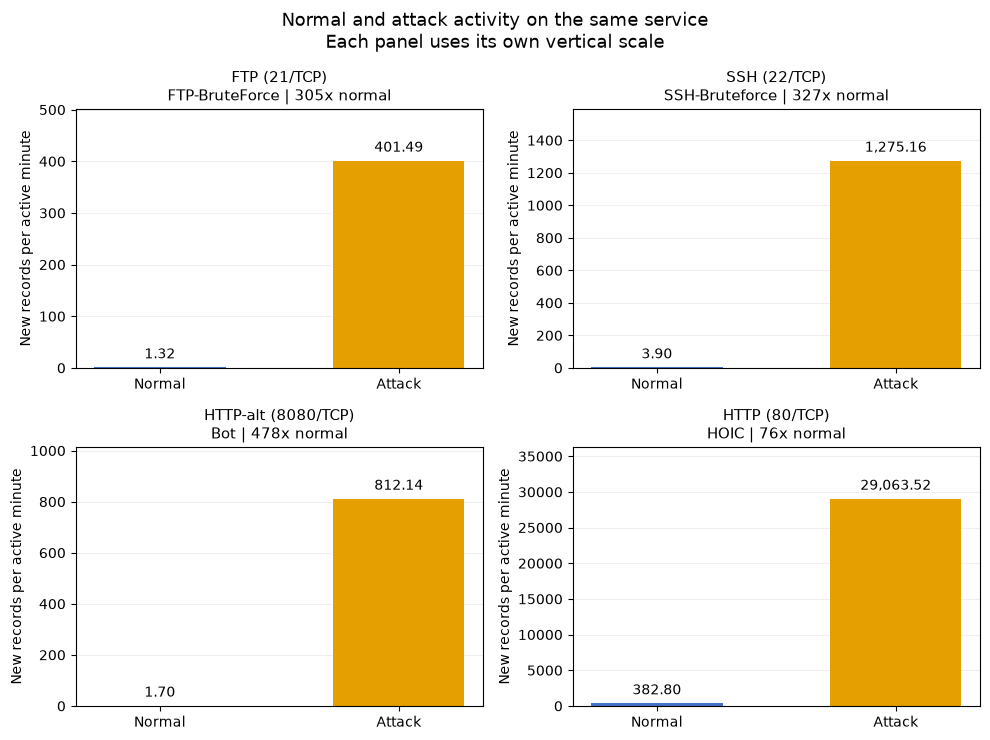

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
fig.suptitle("Normal and attack activity on the same service\nEach panel uses its own vertical scale", fontsize=13)

for ax, row in zip(axes.flat, activity.to_dict("records")):
    values = [row["Normal records/min"], row["Attack records/min"]]
    bars = ax.bar(["Normal", "Attack"], values, color=["#4472C4", "#E69F00"], width=0.55)
    ax.bar_label(bars, labels=[f"{value:,.2f}" for value in values], padding=4)
    ax.set_title(f'{row["Service"]}\n{row["Attack category"]} | {row["Times normal"]} normal', fontsize=11)
    ax.set_ylabel("New records per active minute")
    ax.set_ylim(0, max(values) * 1.25)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(charts_folder / "service_activity.png", dpi=160, bbox_inches="tight")
plt.show()
